In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv(
    "../data/charging_clean.csv",
    parse_dates=["StartDatetime", "EndDatetime"],
)
print(df.shape)
df.head(3)

(72108, 14)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,CalcDuration
0,102,291,1,public institution,0,2021-09-30,17:14:26,2021-10-01,1:21:28,2021-09-30 17:14:26,2021-10-01 01:21:28,487,27.68,487.033333
1,104,191,1,resort,0,2021-09-30,18:22:36,2021-10-01,2:21:03,2021-09-30 18:22:36,2021-10-01 02:21:03,478,55.13,478.450000
2,105,320,1,camping,0,2021-09-30,18:57:46,2021-10-01,0:44:59,2021-09-30 18:57:46,2021-10-01 00:44:59,347,38.45,347.216667


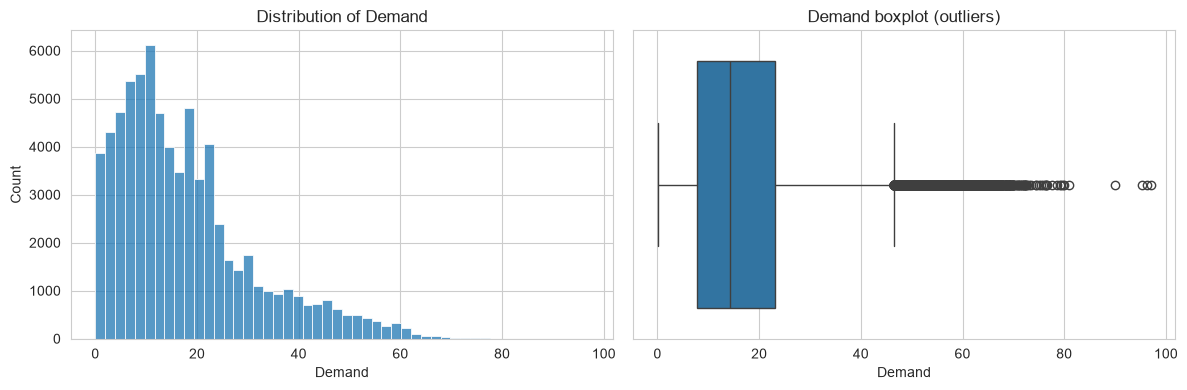

Skewness: 1.195242402789105


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["Demand"], bins=50, ax=axes[0])
axes[0].set_title("Distribution of Demand")

sns.boxplot(x=df["Demand"], ax=axes[1])
axes[1].set_title("Demand boxplot (outliers)")

plt.tight_layout()
plt.show()

print("Skewness:", df["Demand"].skew())

                    count       mean
Location                            
accommodation         185  29.369568
bus garage             29  28.587586
camping              1620  25.667722
apartment           13913  18.814346
public area         13952  18.054652
restaurant           2216  17.861304
public institution   6961  17.550578
resort               8717  17.470545
public parking lot   3364  17.340276
golf                 1026  16.767076
market               2958  16.673347
company              7527  16.301634
sightseeing          1185  15.476169
hotel                8455  14.857642


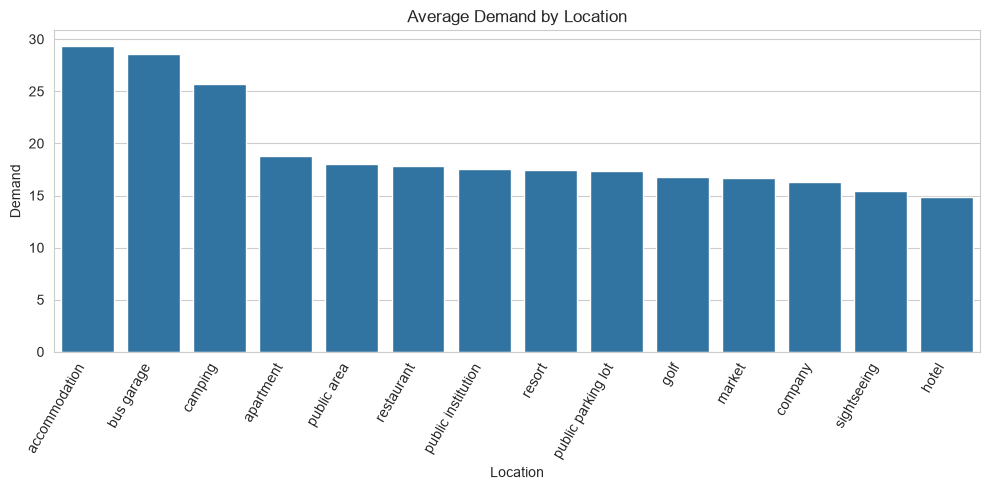


By charger type:
 ChargerType
0    17.147031
1    19.229149
Name: Demand, dtype: float64

By charger company:
 ChargerCompany
0    16.846728
1    18.001804
Name: Demand, dtype: float64


In [3]:
# Average demand and session count per location
loc = df.groupby("Location")["Demand"].agg(["count", "mean"]).sort_values("mean", ascending=False)
print(loc)

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="Location", y="Demand", order=loc.index, errorbar=None)
plt.xticks(rotation=60, ha="right")
plt.title("Average Demand by Location")
plt.tight_layout()
plt.show()

# Charger type and company
print("\nBy charger type:\n", df.groupby("ChargerType")["Demand"].mean())
print("\nBy charger company:\n", df.groupby("ChargerCompany")["Demand"].mean())

C:\Users\91903\AppData\Local\Temp\ipykernel_14384\1789003760.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["DayOfWeek"] = df["StartDatetime"].dt.dayofweek   # 0 = Monday, 6 = Sunday


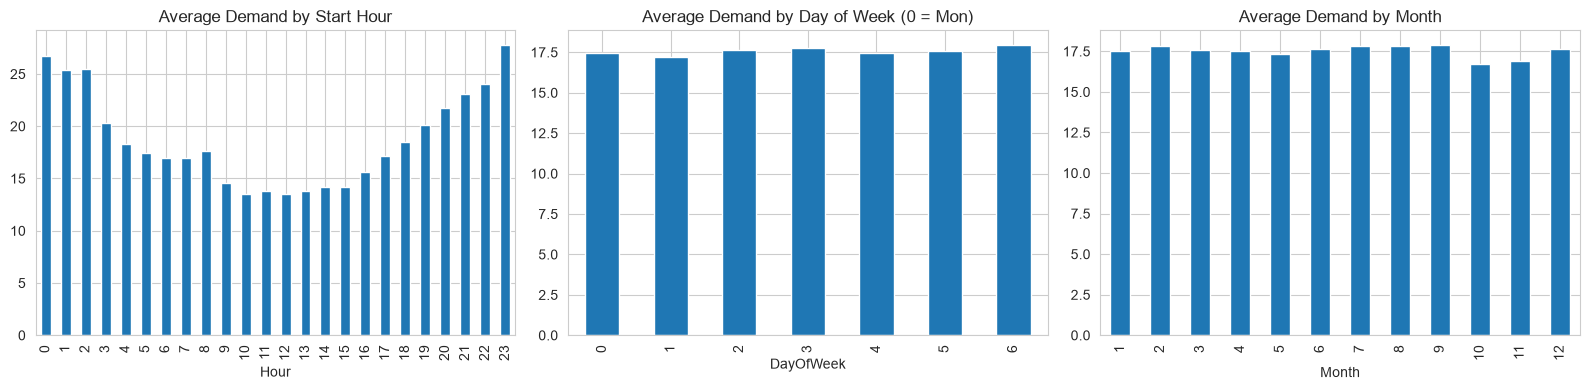

Hour
0      909
1      447
2      195
3      133
4      189
5      543
6     1210
7     2273
8     4109
9     4018
10    3276
11    3144
12    3821
13    3736
14    3845
15    4169
16    5099
17    6293
18    6435
19    5449
20    4704
21    3936
22    2405
23    1770
Name: count, dtype: int64


In [4]:
df["Hour"] = df["StartDatetime"].dt.hour
df["DayOfWeek"] = df["StartDatetime"].dt.dayofweek   # 0 = Monday, 6 = Sunday
df["Month"] = df["StartDatetime"].dt.month

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df.groupby("Hour")["Demand"].mean().plot(kind="bar", ax=axes[0])
axes[0].set_title("Average Demand by Start Hour")

df.groupby("DayOfWeek")["Demand"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Average Demand by Day of Week (0 = Mon)")

df.groupby("Month")["Demand"].mean().plot(kind="bar", ax=axes[2])
axes[2].set_title("Average Demand by Month")

plt.tight_layout()
plt.show()

# How many sessions start in each hour (traffic, not size)
print(df["Hour"].value_counts().sort_index())

In [5]:
print(df.groupby("ChargerType")["Demand"].agg(["count", "mean"]))
print(df.groupby("ChargerCompany")["Demand"].agg(["count", "mean"]))

             count       mean
ChargerType                  
0            57398  17.147031
1            14710  19.229149
                count       mean
ChargerCompany                  
0               26845  16.846728
1               45263  18.001804


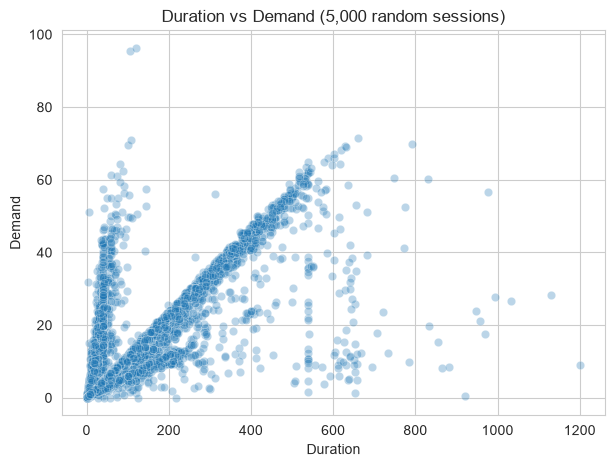

Correlation Duration vs Demand: 0.6549056482987303


In [6]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df.sample(5000, random_state=42), x="Duration", y="Demand", alpha=0.3)
plt.title("Duration vs Demand (5,000 random sessions)")
plt.show()

print("Correlation Duration vs Demand:", df["Duration"].corr(df["Demand"]))

In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/charging_clean.csv",
    parse_dates=["StartDatetime", "EndDatetime"],
)

# Sort by time so "history" only looks backwards
df = df.sort_values("StartDatetime").reset_index(drop=True)

# --- Time features (known before the session starts) ---
df["Hour"] = df["StartDatetime"].dt.hour
df["DayOfWeek"] = df["StartDatetime"].dt.day_of_week   # 0 = Monday
df["Month"] = df["StartDatetime"].dt.month
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

df["TimeOfDay"] = pd.cut(
    df["Hour"],
    bins=[-1, 5, 11, 16, 21, 23],
    labels=["Night", "Morning", "Afternoon", "Evening", "LateEvening"],
)

# --- Historical features (only use PAST sessions, to avoid leakage) ---
df["UserPrevSessions"] = df.groupby("UserID").cumcount()
df["UserPrevAvgDemand"] = df.groupby("UserID")["Demand"].transform(
    lambda s: s.shift().expanding().mean()
)
df["ChargerPrevSessions"] = df.groupby("ChargerID").cumcount()

print(df[["Hour", "DayOfWeek", "IsWeekend", "TimeOfDay",
          "UserPrevSessions", "UserPrevAvgDemand", "ChargerPrevSessions"]].head(10))
print("\nMissing values:\n", df[["UserPrevAvgDemand"]].isnull().sum())

df.to_csv("../data/charging_features.csv", index=False)

   Hour  DayOfWeek  IsWeekend    TimeOfDay  UserPrevSessions  \
0    17          3          0      Evening                 0   
1    18          3          0      Evening                 0   
2    18          3          0      Evening                 0   
3    19          3          0      Evening                 0   
4    20          3          0      Evening                 0   
5    21          3          0      Evening                 0   
6    21          3          0      Evening                 1   
7    21          3          0      Evening                 2   
8    21          3          0      Evening                 0   
9    22          3          0  LateEvening                 0   

   UserPrevAvgDemand  ChargerPrevSessions  
0                NaN                    0  
1                NaN                    0  
2                NaN                    0  
3                NaN                    0  
4                NaN                    0  
5                NaN           

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

models = {
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1, verbose=-1),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    results.append(evaluate(name, y_test, model.predict(X_test)))

results_df = pd.DataFrame(results).round(3).sort_values("RMSE")
results_df

,Model,MAE,MSE,RMSE,R2
5,XGBoost,8.347,131.244,11.456,0.319
2,Random Forest,8.501,133.671,11.562,0.307
6,LightGBM,8.392,134.291,11.588,0.303
3,Decision Tree,8.561,135.724,11.650,0.296
4,Gradient Boosting,8.417,138.597,11.773,0.281
1,Linear Regression,8.745,138.696,11.777,0.281
0,Baseline (mean),10.846,192.904,13.889,-0.001


UserPrevAvgDemand              0.2982
Hour                           0.0792
ChargerType                    0.0649
Location_camping               0.0621
Location_apartment             0.0513
Location_market                0.0478
Location_hotel                 0.0465
Location_public parking lot    0.0364
Location_company               0.0323
Location_restaurant            0.0305
Location_public institution    0.0282
UserPrevSessions               0.0270
TimeOfDay_Morning              0.0266
ChargerCompany                 0.0252
Location_public area           0.0249
dtype: float32


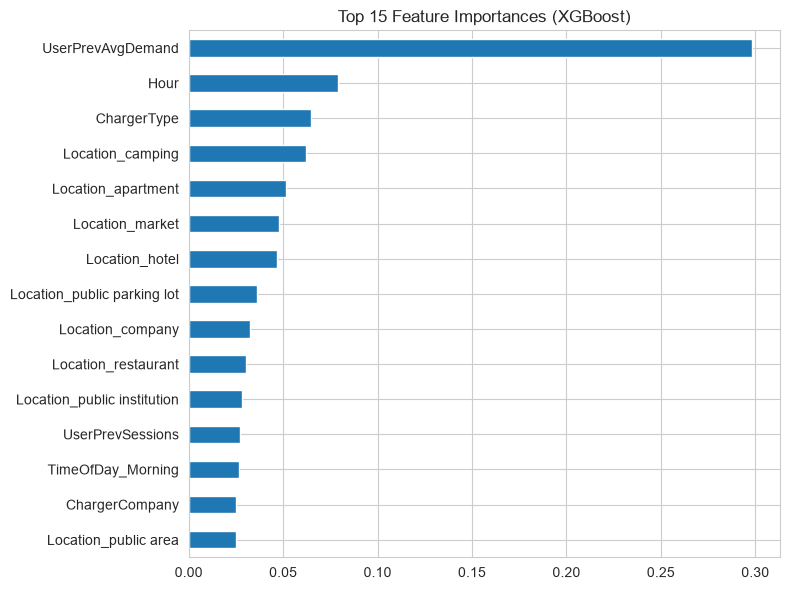

In [ ]:
import matplotlib.pyplot as plt

best = models["XGBoost"]
importance = pd.Series(best.feature_importances_, index=X_train.columns)
top = importance.sort_values(ascending=False).head(15)
print(top.round(4))

top.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 Feature Importances (XGBoost)")
plt.tight_layout()
plt.show()

In [ ]:
import joblib
joblib.dump(best, "../models/xgb_regressor.pkl")
joblib.dump(list(X_train.columns), "../models/regression_columns.pkl")

['../models/regression_columns.pkl']

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/charging_features.csv", parse_dates=["StartDatetime"])
df = df.sort_values("StartDatetime").reset_index(drop=True)

# Same split as regression: first 80% = train, last 20% = test
split = int(len(df) * 0.8)

# Median from TRAIN data only (avoids leakage)
threshold = df["Demand"].iloc[:split].median()
print("Median demand threshold (train):", threshold)

df["HighDemand"] = (df["Demand"] >= threshold).astype(int)

# Check class balance
print("\nOverall:\n", df["HighDemand"].value_counts(normalize=True).round(3))
print("\nTrain:\n", df["HighDemand"].iloc[:split].value_counts(normalize=True).round(3))
print("\nTest:\n", df["HighDemand"].iloc[split:].value_counts(normalize=True).round(3))

Median demand threshold (train): 14.36

Overall:
 HighDemand
0    0.503
1    0.497
Name: proportion, dtype: float64

Train:
 HighDemand
1    0.5
0    0.5
Name: proportion, dtype: float64

Test:
 HighDemand
0    0.513
1    0.487
Name: proportion, dtype: float64


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

df["HasHistory"] = df["UserPrevAvgDemand"].notna().astype(int)

features = [
     "ChargerCompany", "ChargerType", "Location",
    "Hour", "DayOfWeek", "IsWeekend", "TimeOfDay",
    "UserPrevSessions", "UserPrevAvgDemand", "HasHistory", "IsGuest",
    "ChargerPrevSessions",
]

X = pd.get_dummies(df[features], columns=["Location", "TimeOfDay"], drop_first=True)
y = df["HighDemand"]

X_train, X_test = X.iloc[:split].copy(), X.iloc[split:].copy()
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Fill missing history with the TRAIN average only
fill_value = X_train["UserPrevAvgDemand"].mean()
X_train["UserPrevAvgDemand"] = X_train["UserPrevAvgDemand"].fillna(fill_value)
X_test["UserPrevAvgDemand"] = X_test["UserPrevAvgDemand"].fillna(fill_value)

# Scaled copies for models that need them (Logistic Regression, KNN)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

def evaluate_clf(name, y_true, y_pred, y_prob):
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, y_prob)}

clf_results = []

# Models that need scaled data
for name, model in {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
}.items():
    model.fit(X_train_s, y_train)
    clf_results.append(evaluate_clf(name, y_test, model.predict(X_test_s), model.predict_proba(X_test_s)[:, 1]))

# Tree-based models use unscaled data
tree_models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1, verbose=-1),
}
for name, model in tree_models.items():
    model.fit(X_train, y_train)
    clf_results.append(evaluate_clf(name, y_test, model.predict(X_test), model.predict_proba(X_test)[:, 1]))

clf_df = pd.DataFrame(clf_results).round(3).sort_values("ROC-AUC", ascending=False)
clf_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
3,Random Forest,0.715,0.695,0.739,0.717,0.795
4,XGBoost,0.714,0.695,0.736,0.715,0.793
5,LightGBM,0.709,0.705,0.694,0.699,0.791
2,Decision Tree,0.709,0.687,0.739,0.712,0.783
1,KNN,0.703,0.678,0.743,0.709,0.773
0,Logistic Regression,0.697,0.682,0.710,0.695,0.773


In [ ]:
import joblib

joblib.dump(tree_models["Random Forest"], "../models/rf_classifier.pkl")
joblib.dump(list(X_train.columns), "../models/classification_columns.pkl")
joblib.dump(threshold, "../models/demand_threshold.pkl")

['../models/demand_threshold.pkl']

In [ ]:
from sklearn.svm import SVC

# Train on a 15,000-row sample to keep it fast
sample_idx = X_train_s.shape[0]
rng = np.random.RandomState(42)
idx = rng.choice(sample_idx, size=15000, replace=False)

svm = SVC(kernel="rbf", C=1.0, probability=True, random_state=42)
svm.fit(X_train_s[idx], y_train.iloc[idx])

clf_results.append(evaluate_clf(
    "SVM (15k sample)", y_test, svm.predict(X_test_s), svm.predict_proba(X_test_s)[:, 1]
))

pd.DataFrame(clf_results).round(3).sort_values("ROC-AUC", ascending=False)

c:\Users\91903\Downloads\EV Charging Demand Prediction and Usage Pattern Analysis\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
3,Random Forest,0.715,0.695,0.739,0.717,0.795
4,XGBoost,0.714,0.695,0.736,0.715,0.793
5,LightGBM,0.709,0.705,0.694,0.699,0.791
2,Decision Tree,0.709,0.687,0.739,0.712,0.783
0,Logistic Regression,0.697,0.682,0.710,0.695,0.773
1,KNN,0.703,0.678,0.743,0.709,0.773
6,SVM (15k sample),0.703,0.673,0.757,0.713,0.767


In [ ]:
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

# Build an imbalanced TRAIN set: keep all Normal, but only 20% of High
rng = np.random.RandomState(42)
high_idx = y_train[y_train == 1].index
normal_idx = y_train[y_train == 0].index
keep_high = rng.choice(high_idx, size=int(len(high_idx) * 0.2), replace=False)
imb_idx = normal_idx.union(pd.Index(keep_high))

X_imb, y_imb = X_train.loc[imb_idx], y_train.loc[imb_idx]
print("Imbalanced train class share:\n", y_imb.value_counts(normalize=True).round(3))

samplers = {
    "No resampling": None,
    "Random Oversampling": RandomOverSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42),
}

rows = []
for name, sampler in samplers.items():
    if sampler is None:
        Xr, yr = X_imb, y_imb
    else:
        Xr, yr = sampler.fit_resample(X_imb, y_imb)
    model = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42)
    model.fit(Xr, yr)
    rows.append(evaluate_clf(name, y_test, model.predict(X_test), model.predict_proba(X_test)[:, 1]))

pd.DataFrame(rows).round(3)

Imbalanced train class share:
 HighDemand
0    0.833
1    0.167
Name: proportion, dtype: float64


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,No resampling,0.583,0.873,0.167,0.281,0.787
1,Random Oversampling,0.691,0.742,0.560,0.638,0.785
2,SMOTE,0.652,0.768,0.409,0.534,0.778
3,ADASYN,0.644,0.759,0.395,0.520,0.775


c:\Users\91903\Downloads\EV Charging Demand Prediction and Usage Pattern Analysis\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


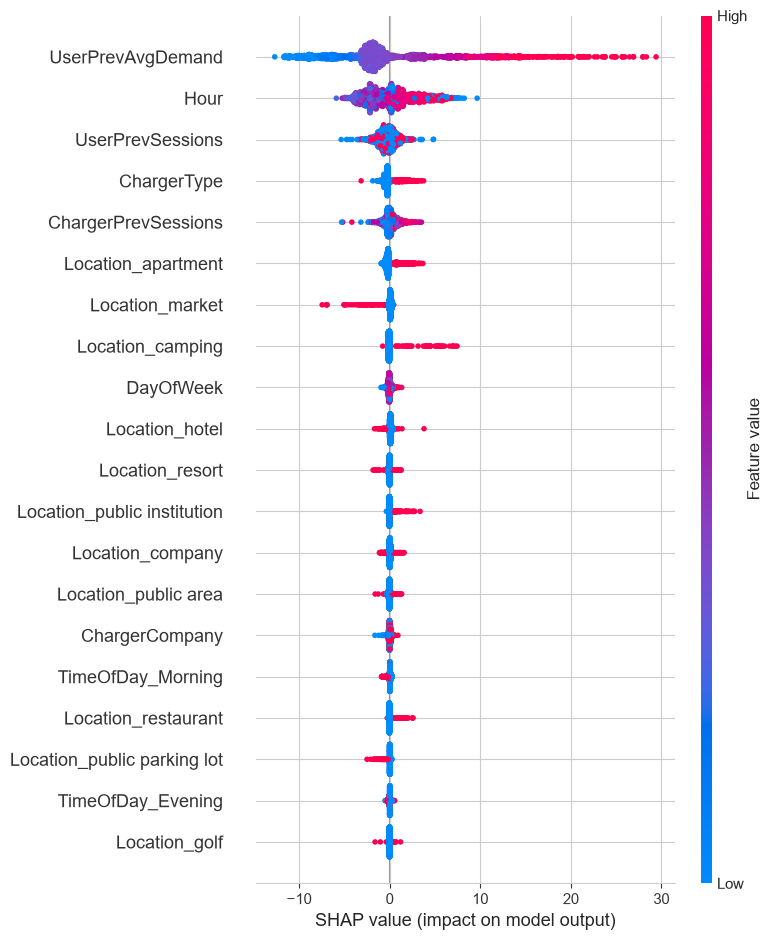

In [ ]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

# Load the saved model and the data
model = joblib.load("../models/xgb_regressor.pkl")
columns = joblib.load("../models/regression_columns.pkl")

df = pd.read_csv("../data/charging_features.csv", parse_dates=["StartDatetime"])
df = df.sort_values("StartDatetime").reset_index(drop=True)
df["HasHistory"] = df["UserPrevAvgDemand"].notna().astype(int)

features = [
     "ChargerCompany", "ChargerType", "Location",
    "Hour", "DayOfWeek", "IsWeekend", "TimeOfDay",
    "UserPrevSessions", "UserPrevAvgDemand", "HasHistory", "IsGuest",
    "ChargerPrevSessions",
]
X = pd.get_dummies(df[features], columns=["Location", "TimeOfDay"], drop_first=True)
X = X.reindex(columns=columns, fill_value=0)

split = int(len(df) * 0.8)
fill_value = X.iloc[:split]["UserPrevAvgDemand"].mean()
X["UserPrevAvgDemand"] = X["UserPrevAvgDemand"].fillna(fill_value)
X_test = X.iloc[split:]

# SHAP on a 2,000-row sample of the test set (keeps it fast)
X_sample = X_test.sample(2000, random_state=42)
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_sample)

# Global view: which features matter and in which direction
shap.summary_plot(shap_values, X_sample, show=False)
plt.tight_layout()
plt.show()

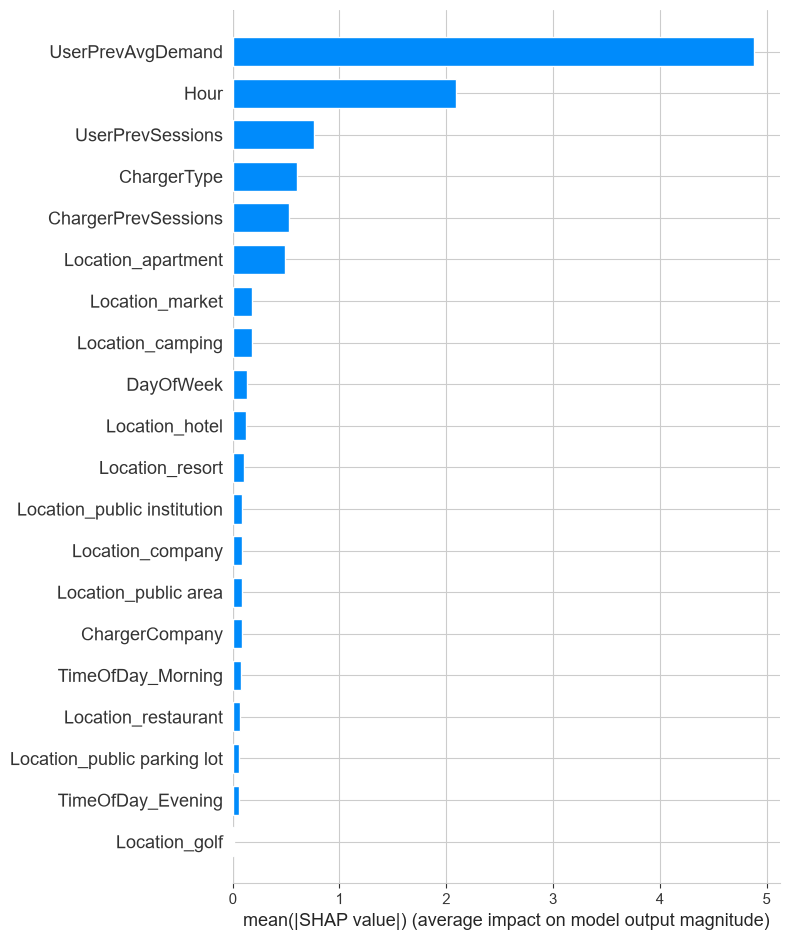

In [ ]:
shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
plt.tight_layout()
plt.show()

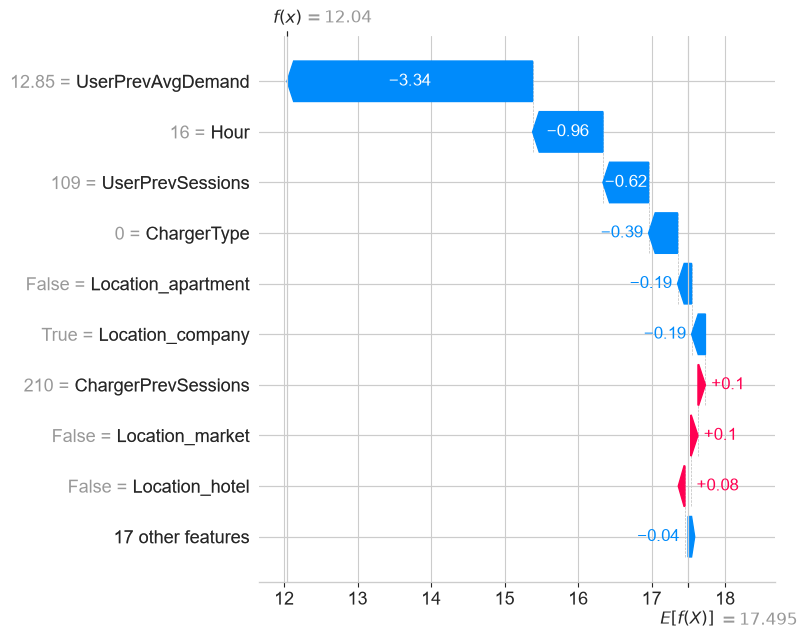

Actual demand: 4.28
Predicted demand: 12.039849


In [ ]:
# Explain the first session in the sample
shap.plots.waterfall(shap_values[0], max_display=10, show=False)
plt.tight_layout()
plt.show()

print("Actual demand:", df.loc[X_sample.index[0], "Demand"])
print("Predicted demand:", model.predict(X_sample.iloc[[0]])[0])

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

clf = joblib.load("../models/rf_classifier.pkl")
clf_columns = joblib.load("../models/classification_columns.pkl")
threshold = joblib.load("../models/demand_threshold.pkl")

Xc = pd.get_dummies(df[features], columns=["Location", "TimeOfDay"], drop_first=True)
Xc = Xc.reindex(columns=clf_columns, fill_value=0)
Xc["UserPrevAvgDemand"] = Xc["UserPrevAvgDemand"].fillna(Xc.iloc[:split]["UserPrevAvgDemand"].mean())
Xc_train, Xc_test = Xc.iloc[:split], Xc.iloc[split:]

lime_explainer = LimeTabularExplainer(
    Xc_train.values.astype(float),
    feature_names=list(Xc_train.columns),
    class_names=["Normal Demand", "High Demand"],
    mode="classification",
)

i = 10  # change this number to explain a different test session
exp = lime_explainer.explain_instance(
    Xc_test.iloc[i].values.astype(float), clf.predict_proba, num_features=10
)
exp.show_in_notebook(show_table=True)
print("Actual demand:", df.loc[Xc_test.index[i], "Demand"], "| Threshold:", threshold)

c:\Users\91903\Downloads\EV Charging Demand Prediction and Usage Pattern Analysis\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


ImportError: cannot import name 'display' from 'IPython.core.display' (c:\Users\91903\Downloads\EV Charging Demand Prediction and Usage Pattern Analysis\venv\Lib\site-packages\IPython\core\display.py)

[('Hour > 19.00', 0.1032924451033497), ('Location_market <= 0.00', 0.09881331160222159), ('ChargerType <= 0.00', -0.07207738402962875), ('TimeOfDay_Night <= 0.00', -0.07123231219590709), ('TimeOfDay_LateEvening > 0.00', 0.07085644275510908), ('Location_bus garage <= 0.00', 0.06977889326591723), ('16.63 < UserPrevAvgDemand <= 17.27', 0.053759184408787006), ('Location_hotel > 0.00', -0.05135461871537715), ('UserPrevSessions > 11502.75', -0.04948471608401319), ('Location_camping <= 0.00', -0.026830092196337335)]


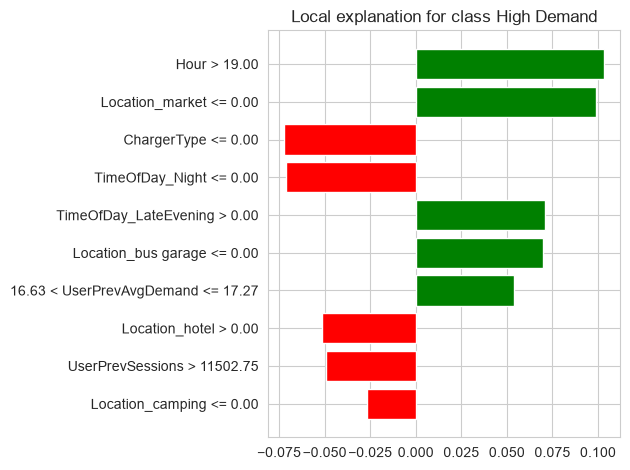

Actual demand: 24.1 | Threshold: 14.36


In [ ]:
from IPython.display import display, HTML

display(HTML(exp.as_html()))

# Also show it as a simple list and a chart
print(exp.as_list())
fig = exp.as_pyplot_figure()
plt.tight_layout()
plt.show()

print("Actual demand:", df.loc[Xc_test.index[i], "Demand"], "| Threshold:", threshold)

In [ ]:
binary_cols = [i for i, c in enumerate(Xc_train.columns)
               if set(Xc_train[c].unique()) <= {0, 1}]

lime_explainer = LimeTabularExplainer(
    Xc_train.values.astype(float),
    feature_names=list(Xc_train.columns),
    class_names=["Normal Demand", "High Demand"],
    categorical_features=binary_cols,
    mode="classification",
)

In [ ]:
print(df["UserID"].value_counts().head(5))
print("\nShare of sessions from UserID 0:", round((df["UserID"] == 0).mean(), 3))
print("\nLocations for UserID 0:\n", df[df["UserID"] == 0]["Location"].value_counts().head())
print("\nDemand for UserID 0:\n", df[df["UserID"] == 0]["Demand"].describe())

UserID
0      31223
31       352
95       348
179      338
40       323
Name: count, dtype: int64

Share of sessions from UserID 0: 0.433

Locations for UserID 0:
 Location
hotel          6481
resort         6380
apartment      5235
public area    5144
company        3981
Name: count, dtype: int64

Demand for UserID 0:
 count    31223.000000
mean        16.761708
std         13.041029
min          0.010000
25%          6.900000
50%         14.230000
75%         22.400000
max         80.000000
Name: Demand, dtype: float64


In [ ]:
# UserID 0 is a catch-all for guests, so it has no real personal history
is_guest = df["UserID"] == 0
df["IsGuest"] = is_guest.astype(int)

df["UserPrevSessions"] = df.groupby("UserID").cumcount()
df.loc[is_guest, "UserPrevSessions"] = 0

df["UserPrevAvgDemand"] = df.groupby("UserID")["Demand"].transform(
    lambda s: s.shift().expanding().mean()
)
df.loc[is_guest, "UserPrevAvgDemand"] = np.nan

df["ChargerPrevSessions"] = df.groupby("ChargerID").cumcount()

print("Missing UserPrevAvgDemand:", df["UserPrevAvgDemand"].isnull().sum())

Missing UserPrevAvgDemand: 33543


In [ ]:
features = [
    "ChargerCompany", "ChargerType", "Location",
    "Hour", "DayOfWeek", "IsWeekend", "TimeOfDay",
    "UserPrevSessions", "UserPrevAvgDemand", "HasHistory", "IsGuest",
    "ChargerPrevSessions",
]

In [9]:
check = pd.read_csv("../data/charging_features.csv", nrows=5)
print(list(check.columns))

['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand', 'CalcDuration', 'Hour', 'DayOfWeek', 'Month', 'IsWeekend', 'TimeOfDay', 'UserPrevSessions', 'UserPrevAvgDemand', 'ChargerPrevSessions']


In [10]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/charging_clean.csv",
    parse_dates=["StartDatetime", "EndDatetime"],
)
df = df.sort_values("StartDatetime").reset_index(drop=True)

# Time features
df["Hour"] = df["StartDatetime"].dt.hour
df["DayOfWeek"] = df["StartDatetime"].dt.day_of_week
df["Month"] = df["StartDatetime"].dt.month
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)
df["TimeOfDay"] = pd.cut(
    df["Hour"],
    bins=[-1, 5, 11, 16, 21, 23],
    labels=["Night", "Morning", "Afternoon", "Evening", "LateEvening"],
)

# History features (UserID 0 is a catch-all for guests)
is_guest = df["UserID"] == 0
df["IsGuest"] = is_guest.astype(int)

df["UserPrevSessions"] = df.groupby("UserID").cumcount()
df.loc[is_guest, "UserPrevSessions"] = 0

df["UserPrevAvgDemand"] = df.groupby("UserID")["Demand"].transform(
    lambda s: s.shift().expanding().mean()
)
df.loc[is_guest, "UserPrevAvgDemand"] = np.nan

df["ChargerPrevSessions"] = df.groupby("ChargerID").cumcount()

print("Missing UserPrevAvgDemand:", df["UserPrevAvgDemand"].isnull().sum())
print("Has IsGuest:", "IsGuest" in df.columns)

df.to_csv("../data/charging_features.csv", index=False)
print("Saved.")

Missing UserPrevAvgDemand: 33543
Has IsGuest: True
Saved.


In [12]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

df = pd.read_csv("../data/charging_features.csv", parse_dates=["StartDatetime"])
df = df.sort_values("StartDatetime").reset_index(drop=True)

# This line will fail if the features file is still the old one
assert "IsGuest" in df.columns, "Run the rebuild cell first (the one that prints Saved.)"

df["HasHistory"] = df["UserPrevAvgDemand"].notna().astype(int)

split = int(len(df) * 0.8)
threshold = df["Demand"].iloc[:split].median()
df["HighDemand"] = (df["Demand"] >= threshold).astype(int)

features = [
    "ChargerCompany", "ChargerType", "Location",
    "Hour", "DayOfWeek", "IsWeekend", "TimeOfDay",
    "UserPrevSessions", "UserPrevAvgDemand", "HasHistory", "IsGuest",
    "ChargerPrevSessions",
]

X = pd.get_dummies(df[features], columns=["Location", "TimeOfDay"], drop_first=True)
y = df["HighDemand"]

X_train, X_test = X.iloc[:split].copy(), X.iloc[split:].copy()
y_train, y_test = y.iloc[:split], y.iloc[split:]

fill_value = X_train["UserPrevAvgDemand"].mean()
X_train["UserPrevAvgDemand"] = X_train["UserPrevAvgDemand"].fillna(fill_value)
X_test["UserPrevAvgDemand"] = X_test["UserPrevAvgDemand"].fillna(fill_value)

def evaluate_clf(name, y_true, y_pred, y_prob):
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, y_prob)}

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Threshold:", threshold)

Train: (57686, 27)  Test: (14422, 27)
Threshold: 14.36


In [13]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Scaled copies for Logistic Regression and KNN
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

clf_results = []

for name, model in {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
}.items():
    model.fit(X_train_s, y_train)
    clf_results.append(evaluate_clf(name, y_test, model.predict(X_test_s), model.predict_proba(X_test_s)[:, 1]))

tree_models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1, verbose=-1),
}
for name, model in tree_models.items():
    model.fit(X_train, y_train)
    clf_results.append(evaluate_clf(name, y_test, model.predict(X_test), model.predict_proba(X_test)[:, 1]))

clf_df = pd.DataFrame(clf_results).round(3).sort_values("ROC-AUC", ascending=False)

# Save the corrected classifier files for the dashboard
joblib.dump(tree_models["Random Forest"], "../models/rf_classifier.pkl")
joblib.dump(list(X_train.columns), "../models/classification_columns.pkl")
joblib.dump(threshold, "../models/demand_threshold.pkl")

clf_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
4,XGBoost,0.715,0.680,0.785,0.729,0.792
3,Random Forest,0.716,0.684,0.772,0.726,0.790
5,LightGBM,0.714,0.681,0.778,0.726,0.790
2,Decision Tree,0.703,0.662,0.796,0.723,0.779
0,Logistic Regression,0.695,0.683,0.698,0.691,0.773
1,KNN,0.697,0.673,0.736,0.703,0.770


In [14]:
import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

dfr = pd.read_csv("../data/charging_features.csv", parse_dates=["StartDatetime"])
dfr = dfr.sort_values("StartDatetime").reset_index(drop=True)
assert "IsGuest" in dfr.columns
dfr["HasHistory"] = dfr["UserPrevAvgDemand"].notna().astype(int)

reg_features = [
    "ChargerCompany", "ChargerType", "Location",
    "Hour", "DayOfWeek", "IsWeekend", "TimeOfDay",
    "UserPrevSessions", "UserPrevAvgDemand", "HasHistory", "IsGuest",
    "ChargerPrevSessions",
]
Xr = pd.get_dummies(dfr[reg_features], columns=["Location", "TimeOfDay"], drop_first=True)
yr = dfr["Demand"]

cut = int(len(dfr) * 0.8)
Xr_train, Xr_test = Xr.iloc[:cut].copy(), Xr.iloc[cut:].copy()
yr_train, yr_test = yr.iloc[:cut], yr.iloc[cut:]

fv = Xr_train["UserPrevAvgDemand"].mean()
Xr_train["UserPrevAvgDemand"] = Xr_train["UserPrevAvgDemand"].fillna(fv)
Xr_test["UserPrevAvgDemand"] = Xr_test["UserPrevAvgDemand"].fillna(fv)
print("Train:", Xr_train.shape, " Test:", Xr_test.shape)

def evaluate_reg(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

reg_results = [evaluate_reg("Baseline (mean)", yr_test, np.full(len(yr_test), yr_train.mean()))]

reg_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1, verbose=-1),
}
for name, m in reg_models.items():
    m.fit(Xr_train, yr_train)
    reg_results.append(evaluate_reg(name, yr_test, m.predict(Xr_test)))

# Save the corrected regression model for the dashboard
joblib.dump(reg_models["XGBoost"], "../models/xgb_regressor.pkl")
joblib.dump(list(Xr_train.columns), "../models/regression_columns.pkl")

pd.DataFrame(reg_results).round(3).sort_values("RMSE")

Train: (57686, 27)  Test: (14422, 27)


,Model,MAE,MSE,RMSE,R2
6,LightGBM,8.363,129.775,11.392,0.327
5,XGBoost,8.361,130.095,11.406,0.325
4,Gradient Boosting,8.506,131.802,11.481,0.316
3,Random Forest,8.499,134.924,11.616,0.300
2,Decision Tree,8.532,135.047,11.621,0.299
1,Linear Regression,8.720,137.944,11.745,0.284
0,Baseline (mean),10.846,192.904,13.889,-0.001


c:\Users\91903\Downloads\EV Charging Demand Prediction and Usage Pattern Analysis\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


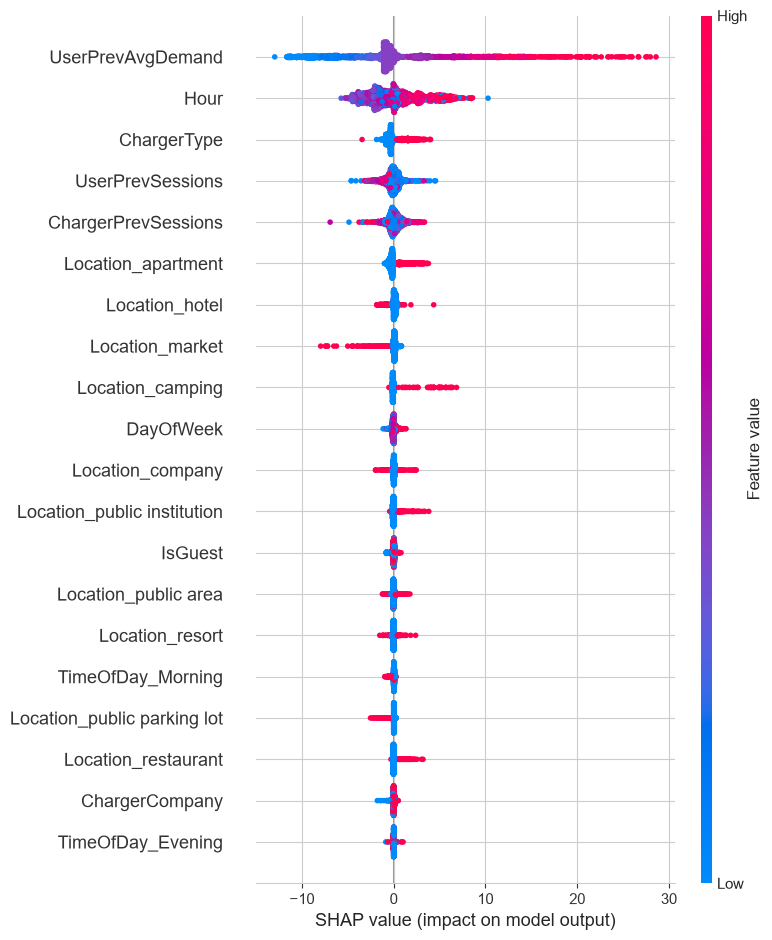

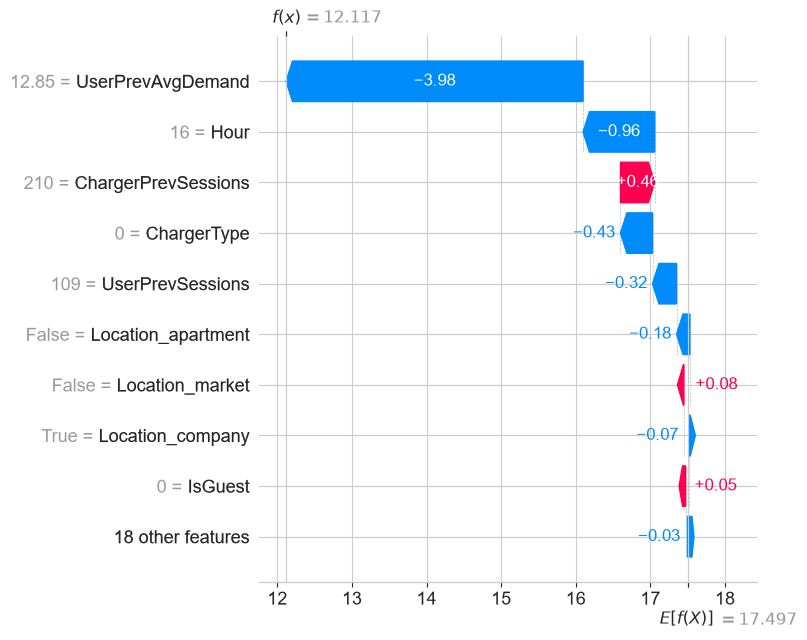

Actual: 4.28 | Predicted: 12.1166


In [15]:
import shap
import matplotlib.pyplot as plt

xgb_model = reg_models["XGBoost"]
X_sample = Xr_test.sample(2000, random_state=42)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_sample)

# Global view
shap.summary_plot(shap_values, X_sample, show=False)
plt.tight_layout()
plt.show()

# One-session explanation
shap.plots.waterfall(shap_values[0], max_display=10, show=False)
plt.tight_layout()
plt.show()
print("Actual:", dfr.loc[X_sample.index[0], "Demand"],
      "| Predicted:", xgb_model.predict(X_sample.iloc[[0]])[0])

[('Hour > 19.00', 0.12113692721498495), ('ChargerType=0', -0.09786467808846425), ('15.16 < UserPrevAvgDemand <= 17.92', 0.08094552199079576), ('Location_market=0', 0.0782627158823198), ('TimeOfDay_LateEvening=1', 0.06856645215227078), ('TimeOfDay_Evening=0', -0.054020876003734515), ('Location_camping=0', -0.04033067580885606), ('Location_apartment=0', -0.0383905519973191), ('HasHistory=0', -0.034540947275561625), ('Location_bus garage=0', -0.022977221121329515)]


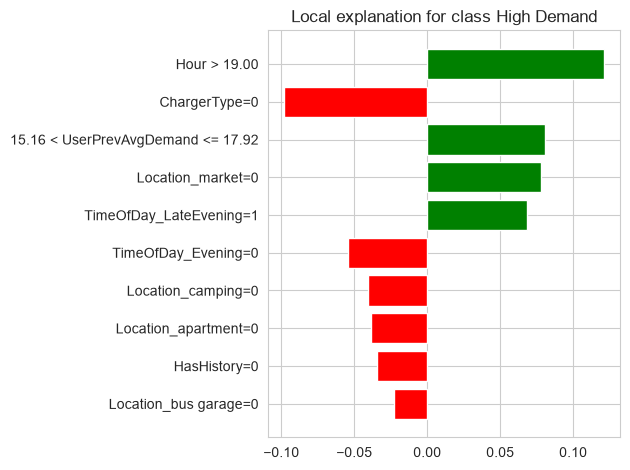

Actual demand: 24.1 | Threshold: 14.36


In [16]:
from lime.lime_tabular import LimeTabularExplainer
from IPython.display import display, HTML

clf = tree_models["Random Forest"]

binary_cols = [i for i, c in enumerate(X_train.columns)
               if set(X_train[c].unique()) <= {0, 1}]

lime_explainer = LimeTabularExplainer(
    X_train.values.astype(float),
    feature_names=list(X_train.columns),
    class_names=["Normal Demand", "High Demand"],
    categorical_features=binary_cols,
    mode="classification",
)

i = 10  # change to explain a different test session
exp = lime_explainer.explain_instance(
    X_test.iloc[i].values.astype(float),
    lambda a: clf.predict_proba(pd.DataFrame(a, columns=X_train.columns)),
    num_features=10,
)

display(HTML(exp.as_html()))
print(exp.as_list())
exp.as_pyplot_figure()
plt.tight_layout()
plt.show()
print("Actual demand:", df.loc[X_test.index[i], "Demand"], "| Threshold:", threshold)